<a href="https://colab.research.google.com/github/ipsitajana2811-png/CoadAlpha_Tasks/blob/main/CodeAlpha_Car_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
from sklearn.metrics import classification_report
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder



In [3]:
#read dataset to pandas dataframe
dataset=pd.read_csv('/content/drive/MyDrive/car data.csv', header=0)


In [4]:
Current_Year=2026
dataset['Car_Age']=Current_Year-dataset['Year']
dataset=dataset.drop(columns=['Year'],errors='ignore')

In [5]:
dataset

,Car_Name,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Car_Age
0,ritz,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,sx4,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,ciaz,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,wagon r,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,swift,4.60,6.87,42450,Diesel,Dealer,Manual,0,12
...,...,...,...,...,...,...,...,...,...
296,city,9.50,11.60,33988,Diesel,Dealer,Manual,0,10
297,brio,4.00,5.90,60000,Petrol,Dealer,Manual,0,11
298,city,3.35,11.00,87934,Petrol,Dealer,Manual,0,17
299,city,11.50,12.50,9000,Diesel,Dealer,Manual,0,9


In [35]:
#print(dataset.describe())
x=dataset.drop(columns=['Selling_Price','Car_Name'])
y=dataset['Selling_Price']


In [36]:
x,y

(     Present_Price  Driven_kms Fuel_Type Selling_type Transmission  Owner  \
 0             5.59       27000    Petrol       Dealer       Manual      0   
 1             9.54       43000    Diesel       Dealer       Manual      0   
 2             9.85        6900    Petrol       Dealer       Manual      0   
 3             4.15        5200    Petrol       Dealer       Manual      0   
 4             6.87       42450    Diesel       Dealer       Manual      0   
 ..             ...         ...       ...          ...          ...    ...   
 296          11.60       33988    Diesel       Dealer       Manual      0   
 297           5.90       60000    Petrol       Dealer       Manual      0   
 298          11.00       87934    Petrol       Dealer       Manual      0   
 299          12.50        9000    Diesel       Dealer       Manual      0   
 300           5.90        5464    Petrol       Dealer       Manual      0   
 
      Car_Age  
 0         12  
 1         13  
 2          9 

In [37]:
categorical_features=['Fuel_Type','Selling_type','Transmission']
numerical_features=['Present_Price','Driven_kms','Owner','Car_Age']

preprocessor=ColumnTransformer (
    transformers=[
        ('num','passthrough',numerical_features),
        ('cat',OneHotEncoder(),categorical_features)
    ]
)

In [87]:
model_pipeline=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('regressor',RandomForestRegressor(n_estimators=100, random_state=42))
])

In [100]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.25,random_state=42)

In [101]:

model_pipeline.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['Present_Price',
                                                   'Driven_kms', 'Owner',
                                                   'Car_Age']),
                                                 ('cat', OneHotEncoder(),
                                                  ['Fuel_Type', 'Selling_type',
                                                   'Transmission'])])),
                ('regressor', RandomForestRegressor(random_state=42))])

In [102]:
y_pred= model_pipeline.predict(x_test)


In [104]:
r2= r2_score(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
print(print(f"Model Accuracy(R2 Score):{r2*100:.2f}%"))
print(f"Average Error (MAE):{mae:.2f}Lakhs")
print(f"Root Mean Squared Error(RMSE):{rmse:2f}")




Model Accuracy(R2 Score):96.68%
None
Average Error (MAE):0.61Lakhs
Root Mean Squared Error(RMSE):0.955503


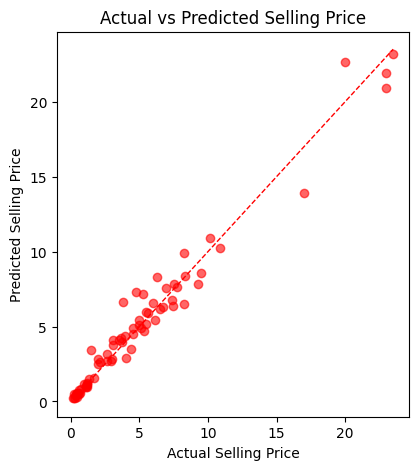

In [105]:
#visualization
plt.figure(figsize=(10,5))
#actual vs predicted plot
plt.subplot(1,2,1)
plt.scatter(y_test,y_pred,alpha=0.6,color= 'red')
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],'r--',lw=1)
plt.xlabel('Actual Selling Price')
plt.ylabel('Predicted Selling Price')
plt.title('Actual vs Predicted Selling Price')
plt.show()
